# Client segmentation by target rate: SOM and alternative clustering methods

This notebook starts from a **per-`obs_id` dataframe**: one row per observation/client record, with predictor features and a binary target. It compares:

- **SOM**: tune map size and training settings, then cluster the SOM codebook vectors.
- **K-means**: tune the number of clusters and initialisation stability.
- **Gaussian mixture models (GMM)**: tune component count and covariance structure.
- **Agglomerative clustering**: tune cluster count and linkage.

The target is excluded from the feature matrix. Clusters are formed from client characteristics; target rates are calculated afterwards to assess whether the resulting groups differ in outcome incidence. This keeps the clustering unsupervised rather than directly optimising clusters against the target.

The notebook uses internal clustering metrics for parameter selection (primarily silhouette, with Davies–Bouldin and Calinski–Harabasz as supporting diagnostics), then reports target rates, confidence intervals, and feature profiles. Do not interpret a higher target rate as causal.

**Input contract:** a dataframe with one row per `obs_id`, a binary target column, and numeric/categorical predictor columns. If multiple rows exist per `obs_id`, aggregate them before using this notebook.

Note the bottom section shows feature differences per cluster per model

## 1. Configuration and imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.decomposition import PCA
from sklearn.model_selection import ParameterGrid

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Update these values to match your dataframe ----
DATA_PATH = Path("working_data/")
TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"  # set to None if unavailable

# Columns that must never enter the clustering feature matrix.
EXCLUDE_COLUMNS = {
    OBS_ID, CUSTOMER_ID, TARGET,
    "target_rule", "total_paid", "payment_count",
    "m0_monthenddate", "transactiondate",
}

RANDOM_STATE = 0
MAX_SILHOUETTE_ROWS = 8000  # silhouette is sampled above this size
BOOTSTRAP_REPEATS = 500
MIN_CLUSTER_SIZE = 0.01     # reject solutions with clusters below 1% of rows
MAX_FEATURES_FOR_PLOTS = 20
OUT_DIR = Path("client_cluster_analysis_full_dataset")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# If you already have the dataframe in memory, replace the loading cell below
# with: df = your_dataframe.copy()


## 2. Load and validate the per-`obs_id` dataframe

In [4]:
from build_dataset import load_dataset
from select_features import prune, stable_groups, compare_sets

D = load_dataset("dataset")
X, y, groups, tr, te = D["X_all"], D["y"], D["groups"], D["train"], D["test"]

"""
# 1. drop constants, aliases and correlated duplicates (train rows only)
pr = prune(X, tr, y)
print(pr["table"].reason.value_counts())

# 2. which families keep mattering on customers the model hasn't seen (grouped CV inside train)
st_knn   = stable_groups(X, y, groups, tr, pr["groups"], kind="knn",   n_splits=10, min_t=2.0)
st_logit = stable_groups(X, y, groups, tr, pr["groups"], kind="logit", n_splits=10, min_t=2.0)
keep = sorted(set(st_knn["keep"]) | set(st_logit["keep"]))      # union of the two judges
print(len(keep), "selected")
print(st_knn["table"].head(20))

# 3. same split, same models, fewer inputs
sets = {
    "all":      list(X.columns),
    "pruned":   pr["keep"],
    "selected": keep,
    "static":   list(D["X_static"].columns),        # the point-in-time baseline
}
print(compare_sets(X, y, groups, tr, te, sets)) 
"""

'\n# 1. drop constants, aliases and correlated duplicates (train rows only)\npr = prune(X, tr, y)\nprint(pr["table"].reason.value_counts())\n\n# 2. which families keep mattering on customers the model hasn\'t seen (grouped CV inside train)\nst_knn   = stable_groups(X, y, groups, tr, pr["groups"], kind="knn",   n_splits=10, min_t=2.0)\nst_logit = stable_groups(X, y, groups, tr, pr["groups"], kind="logit", n_splits=10, min_t=2.0)\nkeep = sorted(set(st_knn["keep"]) | set(st_logit["keep"]))      # union of the two judges\nprint(len(keep), "selected")\nprint(st_knn["table"].head(20))\n\n# 3. same split, same models, fewer inputs\nsets = {\n    "all":      list(X.columns),\n    "pruned":   pr["keep"],\n    "selected": keep,\n    "static":   list(D["X_static"].columns),        # the point-in-time baseline\n}\nprint(compare_sets(X, y, groups, tr, te, sets)) \n'

In [5]:
keep = ['arrears_share_of_due',
 'bal7_ratio_last',
 'cash_share_of_spend',
 'committed_share_of_spend',
 'crccreditlimit_slog',
 'days_since_last_income',
 'grp_debt_repayment_share',
 'income_cv',
 'income_type_p0_rank',
 'm0_arrearsamount_slog',
 'm0_start_cd_group_CD 1',
 'm0_start_cd_group_CD 3',
 'm0_total_due_with_arrears_slog',
 'n_spend_groups_used',
 'no_complete_cycle',
 'no_income_detected',
 'no_income_seen',
 'pay_frequency_weekly',
 'product_group_NPDM',
 'recent_vs_avg_income',
 'run_grp_debt_repayment_slog',
 'run_in_income_employment_slog',
 'run_in_income_informal_slog',
 'run_income_slog',
 'run_n_bounced',
 'run_n_fees',
 'run_n_purchases',
 'run_nonessential_slog',
 'unemployed_now']

In [6]:
Xi = X[keep].copy()

## 3. Prepare predictors

Numeric variables are median-imputed and standardised. Categorical variables are mode-imputed and one-hot encoded. Constant and all-missing columns are removed. The target, identifiers, dates, and known outcome-derived fields are excluded.

For very wide data, one-hot encoding can increase dimensionality. The notebook reports the resulting size so this can be reviewed before fitting.

In [7]:
excluded = set(EXCLUDE_COLUMNS)
if CUSTOMER_ID is not None:
    excluded.add(CUSTOMER_ID)

feature_cols = [c for c in Xi.columns if c not in excluded]
X_raw = Xi.copy()
obs_ids = Xi.copy().reset_index()[OBS_ID]

# Convert booleans to numeric; remove columns with no usable variation.
for c in X_raw.select_dtypes(include=["bool"]).columns:
    X_raw[c] = X_raw[c].astype("int8")

numeric_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]

numeric_cols = [
    c for c in numeric_cols
    if X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
]
categorical_cols = [
    c for c in categorical_cols
    if X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
]
X_raw = X_raw[numeric_cols + categorical_cols]

transformers = []
if numeric_cols:
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    transformers.append(("numeric", numeric_pipe, numeric_cols))
if categorical_cols:
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    transformers.append(("categorical", categorical_pipe, categorical_cols))

if not transformers:
    raise ValueError("No usable predictor columns remain after exclusions.")

preprocessor = ColumnTransformer(transformers, remainder="drop")
X = preprocessor.fit_transform(X_raw)
X = np.asarray(X, dtype=np.float32)

if not np.isfinite(X).all():
    raise ValueError("Preprocessed feature matrix contains non-finite values.")

feature_names = preprocessor.get_feature_names_out()
print("Raw predictors:", X_raw.shape[1])
print("Encoded predictors:", X.shape[1])
print("Matrix shape:", X.shape)


Raw predictors: 29
Encoded predictors: 29
Matrix shape: (247285, 29)


## 4. Shared evaluation functions

Silhouette is the primary tuning criterion. Davies–Bouldin is better when lower; Calinski–Harabasz is better when higher. Scores are computed on a consistent random sample when the dataset is large.

A candidate is rejected if it produces fewer than two clusters, one cluster, or a very small cluster. The minimum-size threshold is configurable above.

In [8]:
def evaluate_labels(Z, labels, max_rows=MAX_SILHOUETTE_ROWS, seed=RANDOM_STATE):
    labels = np.asarray(labels)
    unique, counts = np.unique(labels, return_counts=True)
    n_clusters = len(unique)
    if n_clusters < 2 or n_clusters >= len(labels):
        return None
    #if counts.min() / len(labels) < MIN_CLUSTER_SIZE:
    #    print("Not counted due to cluster size")
    #    return None

    if len(Z) > max_rows:
        rng = np.random.default_rng(seed)
        idx = rng.choice(len(Z), size=max_rows, replace=False)
        Z_eval = Z[idx]
        labels_eval = labels[idx]
        if len(np.unique(labels_eval)) < 2:
            return None
    else:
        Z_eval, labels_eval = Z, labels

    return {
        "n_clusters": n_clusters,
        "silhouette": silhouette_score(Z_eval, labels_eval),
        "davies_bouldin": davies_bouldin_score(Z_eval, labels_eval),
        "calinski_harabasz": calinski_harabasz_score(Z_eval, labels_eval),
        "min_cluster_share": counts.min() / len(labels),
    }


def make_result_row(method, params, scores):
    return {"method": method, **params, **scores}


def cluster_rate_table(labels, target, ids=None):
    tmp = pd.DataFrame({
        "cluster": np.asarray(labels),
        "target": np.asarray(target),
    }, index=ids)
    out = tmp.groupby("cluster").agg(
        n=("target", "size"),
        positives=("target", "sum"),
        target_rate=("target", "mean"),
    )
    out["share"] = out["n"] / len(tmp)
    out["rate_minus_overall"] = out["target_rate"] - tmp["target"].mean()
    return out.sort_values("target_rate", ascending=False)


def bootstrap_rate_intervals(labels, target, repeats=BOOTSTRAP_REPEATS, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    tmp = pd.DataFrame({"cluster": np.asarray(labels), "target": np.asarray(target)})
    rows = []
    for cluster_id, part in tmp.groupby("cluster"):
        vals = part["target"].to_numpy()
        boot = np.array([
            rng.choice(vals, size=len(vals), replace=True).mean()
            for _ in range(repeats)
        ])
        rows.append({
            "cluster": cluster_id,
            "rate": vals.mean(),
            "ci_lower": np.quantile(boot, 0.025),
            "ci_upper": np.quantile(boot, 0.975),
        })
    return pd.DataFrame(rows).set_index("cluster")


## 5. K-means: tune the number of clusters and initialisation

In [13]:
# Candidate k values adapt to the number of observations.
n = len(X)
k_max = min(15, max(5, int(np.sqrt(n / 2))))
k_values = [6]

kmeans_rows = []
kmeans_models = {}
for k in k_values:

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=RANDOM_STATE,
        algorithm="lloyd",
    )
    labels = model.fit_predict(X)
    scores = evaluate_labels(X, labels)

    if scores is not None:
        params = {"k": k, "n_init": 20}
        kmeans_rows.append(make_result_row("kmeans", params, scores))
        kmeans_models[k] = (model, labels)

kmeans_results = pd.DataFrame(kmeans_rows).sort_values(
    ["silhouette", "davies_bouldin"], ascending=[False, True]
)
display(kmeans_results)
if kmeans_results.empty:
    raise RuntimeError("No valid K-means solution. Review feature scaling or MIN_CLUSTER_SIZE.")


,method,k,n_init,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
0,kmeans,6,20,6,0.121618,2.03819,888.452393,0.053347


## 6. Gaussian mixture models: tune components and covariance structure

GMMs provide soft membership probabilities as well as hard cluster assignments. BIC is used as the model-selection criterion within the GMM family; silhouette and cluster-size checks are also reported for comparability.

In [11]:
gmm_rows = []
gmm_models = {}
GMM_TUNING_MAX_ROWS = 15000
if n > GMM_TUNING_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    gmm_idx = np.sort(rng.choice(n, GMM_TUNING_MAX_ROWS, replace=False))
else:
    gmm_idx = np.arange(n)
X_gmm = X[gmm_idx]
component_values = range(5, min(7, max(3, int(np.sqrt(len(X_gmm) / 2)))) + 1)
covariance_types = ["full", "tied", "diag", "spherical"]

for covariance_type in covariance_types:
    for components in component_values:
        try:
            model = GaussianMixture(
                n_components=components,
                covariance_type=covariance_type,
                n_init=3,
                reg_covar=1e-5,
                random_state=RANDOM_STATE,
            )
            labels = model.fit_predict(X_gmm)
            scores = evaluate_labels(X_gmm, labels)
            if scores is None:
                continue
            params = {
                "components": components,
                "covariance_type": covariance_type,
                "bic": model.bic(X_gmm),
                "aic": model.aic(X_gmm),
            }
            gmm_rows.append(make_result_row("gmm", params, scores))
            gmm_models[(components, covariance_type)] = (model, labels)
        except (ValueError, np.linalg.LinAlgError):
            continue

gmm_results = pd.DataFrame(gmm_rows)
if not gmm_results.empty:
    display(gmm_results.sort_values(["bic", "silhouette"], ascending=[True, False]))
else:
    print("No valid GMM candidate. This can happen with high-dimensional or highly collinear data.")


,method,components,covariance_type,bic,aic,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
2,gmm,7,full,-8.935024e+04,-1.141321e+05,7,0.072977,3.970084,536.435242,0.014000
1,gmm,6,full,3.077859e+04,9.538108e+03,6,0.083598,3.287285,492.107605,0.004667
0,gmm,5,full,7.975992e+04,6.206079e+04,5,0.106372,3.060728,743.546631,0.059200
5,gmm,7,diag,1.156693e+05,1.125316e+05,7,0.096165,2.949407,645.421631,0.012067
4,gmm,6,diag,1.784367e+05,1.757483e+05,6,0.097505,2.234842,741.846191,0.050467
3,gmm,5,diag,2.736958e+05,2.714567e+05,5,0.129126,2.722085,772.331299,0.059200
8,gmm,7,spherical,1.046709e+06,1.045064e+06,7,0.047339,2.609528,688.239624,0.060267
7,gmm,6,spherical,1.055787e+06,1.054378e+06,6,0.066147,2.210877,748.113708,0.036067
6,gmm,5,spherical,1.072787e+06,1.071615e+06,5,0.069638,2.633020,833.995728,0.060133


## 7. Agglomerative clustering: tune cluster count and linkage

Ward linkage is evaluated with Euclidean distance. Average and complete linkage are also tested with Euclidean distance. For large datasets, hierarchical clustering can be expensive; the optional cap below allows a reproducible tuning sample. If sampling is used, the final model is refitted on the full dataset only if computationally feasible.

In [12]:
AGGLOMERATIVE_MAX_ROWS = 12000
if n > AGGLOMERATIVE_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    agg_idx = np.sort(rng.choice(n, AGGLOMERATIVE_MAX_ROWS, replace=False))
else:
    agg_idx = np.arange(n)

X_agg = X[agg_idx]
agg_rows = []
agg_models = {}
agg_k_max = min(10, max(5, int(np.sqrt(len(X_agg) / 2))))

for linkage in ["ward", "average", "complete"]:
    for k in range(5, 7):
        try:
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage)
            labels = model.fit_predict(X_agg)
            scores = evaluate_labels(X_agg, labels)
            if scores is None:
                continue
            params = {"k": k, "linkage": linkage, "tuning_n": len(X_agg)}
            agg_rows.append(make_result_row("agglomerative", params, scores))
            agg_models[(k, linkage)] = (model, labels)
        except (ValueError, MemoryError):
            continue

agg_results = pd.DataFrame(agg_rows)
if not agg_results.empty:
    display(agg_results.sort_values(
        ["silhouette", "davies_bouldin"], ascending=[False, True]
    ))
else:
    print("No valid agglomerative candidate.")


,method,k,linkage,tuning_n,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
2,agglomerative,5,average,12000,5,0.464599,0.550951,12.237767,0.000083
3,agglomerative,6,average,12000,6,0.379950,0.673860,12.338259,0.000083
4,agglomerative,5,complete,12000,5,0.281386,1.434464,228.976898,0.000083
5,agglomerative,6,complete,12000,6,0.280758,1.293327,185.600647,0.000083
1,agglomerative,6,ward,12000,6,0.105802,2.327577,721.498718,0.048750
0,agglomerative,5,ward,12000,5,0.100026,2.470672,786.239502,0.059833


## 8. SOM: tune map size and training settings

The SOM is trained on the same preprocessed feature matrix. Map dimensions are generated from dataset size rather than fixed in advance. A small candidate set of map sizes, neighbourhood radii, learning rates, and training lengths is evaluated.

For each SOM candidate:
1. Quantisation error measures how closely observations match their best-matching units (BMUs).
2. Topographic error measures how often the first and second BMUs are not adjacent.
3. The codebook vectors are clustered with K-means; the resulting observation labels are evaluated using silhouette.

Install `MiniSom` if it is not already available.

In [12]:
%pip -q install MiniSom

Note: you may need to restart the kernel to use updated packages.


In [14]:
from minisom import MiniSom

# Map-size candidates scale with n. Keep the grid compact enough to avoid
# creating many nearly empty neurons.
base_side = max(3, int(round(np.sqrt(np.sqrt(n)))))
map_sides = sorted(set([
    max(3, base_side - 2),
    base_side,
    min(20, base_side + 2),
]))
som_map_shapes = [(side, side) for side in map_sides[:2]]

# Parameter candidates are deliberately varied; the best combination is selected
# using quantisation/topographic error and downstream codebook-cluster silhouette.
som_sigmas = [max(0.8, side / 4) for side in map_sides]
som_learning_rates = [0.2, 0.5]
som_epochs = [20, 50]
som_cluster_counts = sorted(set([4, 5, 6, 7]))
som_cluster_counts = [k for k in som_cluster_counts if k < n]

# Use a deterministic subset for SOM hyperparameter search if n is very large.
SOM_TUNING_MAX_ROWS = 12000
if n > SOM_TUNING_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    som_idx = np.sort(rng.choice(n, SOM_TUNING_MAX_ROWS, replace=False))
else:
    som_idx = np.arange(n)
X_som_tune = X[som_idx]

som_rows = []
som_candidates = {}
for rows, cols in som_map_shapes:
    for sigma in sorted(set([max(0.8, min(rows, cols) / 4), max(1.0, min(rows, cols) / 2)])):
        for learning_rate in som_learning_rates:
            for epochs in som_epochs:
                som = MiniSom(
                    x=rows, y=cols, input_len=X.shape[1],
                    sigma=sigma, learning_rate=learning_rate,
                    neighborhood_function="gaussian",
                    random_seed=RANDOM_STATE,
                )
                som.random_weights_init(X_som_tune)
                som.train_random(X_som_tune, num_iteration=epochs * len(X_som_tune))

                bmu = np.array([som.winner(row) for row in X_som_tune])
                bmu_flat = bmu[:, 0] * cols + bmu[:, 1]
                qe = som.quantization_error(X_som_tune)
                te = som.topographic_error(X_som_tune)

                codebook = som.get_weights().reshape(rows * cols, X.shape[1])
                # Exclude unused neurons when assigning codebook clusters.
                occupied = np.unique(bmu_flat)
                occupied_vectors = codebook[occupied]

                for k in som_cluster_counts:
                    if k >= len(occupied):
                        continue
                    km_codebook = KMeans(
                        n_clusters=k, n_init=10, random_state=RANDOM_STATE
                    )
                    neuron_labels = km_codebook.fit_predict(occupied_vectors)
                    neuron_to_cluster = dict(zip(occupied, neuron_labels))
                    obs_labels = np.array([neuron_to_cluster[u] for u in bmu_flat])
                    scores = evaluate_labels(X_som_tune, obs_labels)
                    if scores is None:
                        continue

                    params = {
                        "rows": rows, "cols": cols, "sigma": sigma,
                        "learning_rate": learning_rate, "epochs": epochs,
                        "cluster_k": k, "quantization_error": qe,
                        "topographic_error": te,
                    }
                    som_rows.append(make_result_row("som", params, scores))
                    som_candidates[(rows, cols, sigma, learning_rate, epochs, k)] = {
                        "som": som, "km_codebook": km_codebook,
                        "occupied": occupied, "neuron_labels": neuron_labels,
                        "tuning_labels": obs_labels,
                    }

som_results = pd.DataFrame(som_rows)
if som_results.empty:
    print("No valid SOM candidate. Consider reducing MIN_CLUSTER_SIZE or expanding the candidate ranges.")
else:
    display(som_results.sort_values(
        ["silhouette", "quantization_error", "topographic_error"],
        ascending=[False, True, True]
    ).head(20))

,method,rows,cols,sigma,learning_rate,epochs,cluster_k,quantization_error,topographic_error,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
47,som,22,22,5.5,0.5,50,7,3.242587,0.031000,7,0.108499,2.125151,745.510681,0.045083
3,som,20,20,5.0,0.2,20,7,3.189956,0.019750,7,0.106591,2.208141,744.372925,0.058917
46,som,22,22,5.5,0.5,50,6,3.242587,0.031000,6,0.104875,2.279218,794.907715,0.060083
2,som,20,20,5.0,0.2,20,6,3.189956,0.019750,6,0.103372,2.295752,802.242737,0.058917
11,som,20,20,5.0,0.5,20,7,3.213286,0.030250,7,0.101611,2.253967,728.330261,0.059417
43,som,22,22,5.5,0.5,20,7,3.226812,0.030000,7,0.101335,2.269437,704.220947,0.056417
45,som,22,22,5.5,0.5,50,5,3.242587,0.031000,5,0.100002,2.382802,877.483948,0.060083
0,som,20,20,5.0,0.2,20,4,3.189956,0.019750,4,0.099036,2.440924,964.326843,0.097083
9,som,20,20,5.0,0.5,20,5,3.213286,0.030250,5,0.098958,2.359652,795.318787,0.074000
1,som,20,20,5.0,0.2,20,5,3.189956,0.019750,5,0.097585,2.322821,862.539856,0.086000


## 9. Compare candidate methods and select representative solutions

The top candidate from each family is retained for comparison. Silhouette is the primary ranking metric; the other internal metrics and SOM errors are retained to make trade-offs visible. A single metric should not be treated as proof that a clustering is meaningful.

In [15]:
def gini_scores(labels, y):
    """Gini impurity of the target inside the clusters (lower = purer) and the gain over no clustering."""
    labels, y = np.asarray(labels), np.asarray(y)
    ct = pd.crosstab(labels, y).to_numpy().astype(float)            # clusters x target classes
    n = ct.sum()
    size = ct.sum(1) / n
    p = ct / ct.sum(1, keepdims=True)
    weighted = float((size * (1 - (p ** 2).sum(1))).sum())           # size-weighted Gini impurity
    base = 1 - ((ct.sum(0) / n) ** 2).sum()                          # impurity with a single cluster
    return {"gini_impurity": weighted,
            "gini_gain": base - weighted,                            # higher = clusters separate the target better
            "gini_gain_rel": (base - weighted) / base if base > 0 else np.nan}

y_arr = np.asarray(y)

def som_labels_for(key):
    rows_, cols_ = key[0], key[1]
    c = som_candidates[key]
    som_, occ, nl = c["som"], c["occupied"], c["neuron_labels"]
    w = som_.get_weights().reshape(rows_ * cols_, X.shape[1])
    n2c = dict(zip(occ, nl))
    bmu = np.array([som_.winner(r) for r in X])
    flat = bmu[:, 0] * cols_ + bmu[:, 1]
    for u in np.unique(flat):
        if u not in n2c:
            n2c[u] = nl[np.argmin(np.linalg.norm(w[occ] - w[u], axis=1))]
    return np.array([n2c[u] for u in flat])

# add the Gini columns to each results table
if kmeans_results is not None and not kmeans_results.empty:
    g = [gini_scores(kmeans_models[int(r.k)][1], y_arr) for r in kmeans_results.itertuples()]
    kmeans_results = pd.concat([kmeans_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

if gmm_results is not None and not gmm_results.empty:
    g = [gini_scores(gmm_models[(int(r.components), r.covariance_type)][0].predict(X), y_arr)
         for r in gmm_results.itertuples()]
    gmm_results = pd.concat([gmm_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

if agg_results is not None and not agg_results.empty:      # tuned on a sample: score against the sample's target
    g = [gini_scores(agg_models[(int(r.k), r.linkage)][1], y_arr[agg_idx]) for r in agg_results.itertuples()]
    agg_results = pd.concat([agg_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

if som_results is not None and not som_results.empty:      # slowest part: one pass over X per SOM candidate
    keys = [(int(r.rows), int(r.cols), float(r.sigma), float(r.learning_rate), int(r.epochs), int(r.cluster_k))
            for r in som_results.itertuples()]
    g = [gini_scores(som_labels_for(k), y_arr) for k in keys]
    som_results = pd.concat([som_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

In [16]:
candidate_tables = []
for table in [kmeans_results, gmm_results, agg_results, som_results]:
    if table is not None and not table.empty:
        candidate_tables.append(table)

all_results = pd.concat(candidate_tables, ignore_index=True, sort=False)
display(all_results.sort_values(
    ["gini_gain", "silhouette"], ascending=[False, False]
).head(30))

best_by_method = {}
if not kmeans_results.empty:
    r = kmeans_results.sort_values("silhouette", ascending=False).iloc[0]
    best_by_method["kmeans"] = kmeans_models[int(r["k"])][1]

if not gmm_results.empty:
    r = gmm_results.sort_values(["bic", "silhouette"], ascending=[True, False]).iloc[0]
    key = (int(r["components"]), r["covariance_type"])
    best_by_method["gmm"] = gmm_models[key][0].predict(X)

if not agg_results.empty:
    r = agg_results.sort_values("silhouette", ascending=False).iloc[0]
    key = (int(r["k"]), r["linkage"])
    # If tuned on a sample, only sample labels are available here.
    best_by_method["agglomerative_sample"] = (agg_idx, agg_models[key][1])

if not som_results.empty:
    r = som_results.sort_values(
        ["silhouette", "quantization_error", "topographic_error"],
        ascending=[False, True, True]
    ).iloc[0]
    key = (
        int(r["rows"]), int(r["cols"]), float(r["sigma"]),
        float(r["learning_rate"]), int(r["epochs"]), int(r["cluster_k"])
    )
    chosen = som_candidates[key]
    chosen_som = chosen["som"]
    chosen_rows, chosen_cols = key[0], key[1]
    occupied = chosen["occupied"]
    neuron_labels = chosen["neuron_labels"]
    neuron_to_cluster = dict(zip(occupied, neuron_labels))
    full_bmu = np.array([chosen_som.winner(row) for row in X])
    full_bmu_flat = full_bmu[:, 0] * chosen_cols + full_bmu[:, 1]
    # A neuron not occupied during tuning is assigned to its nearest occupied
    # codebook vector, so every observation receives a cluster.
    occupied_vectors = chosen_som.get_weights().reshape(
        chosen_rows * chosen_cols, X.shape[1]
    )[occupied]
    all_weights = chosen_som.get_weights().reshape(
        chosen_rows * chosen_cols, X.shape[1]
    )
    for neuron_id in np.unique(full_bmu_flat):
        if neuron_id not in neuron_to_cluster:
            nearest = np.argmin(
                np.linalg.norm(occupied_vectors - all_weights[neuron_id], axis=1)
            )
            neuron_to_cluster[neuron_id] = neuron_labels[nearest]
    best_by_method["som"] = np.array(
        [neuron_to_cluster[u] for u in full_bmu_flat]
    )

print("Selected:", list(best_by_method))


,method,k,n_init,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,gini_impurity,gini_gain,...,linkage,tuning_n,rows,cols,sigma,learning_rate,epochs,cluster_k,quantization_error,topographic_error
0,kmeans,6.0,20.0,6,0.121618,2.038190,888.452393,0.053347,0.429956,0.069307,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70,som,NaN,NaN,6,0.072314,2.518875,734.346191,0.082167,0.431965,0.067297,...,NaN,NaN,22.0,22.0,11.0,0.2,50.0,6.0,3.699375,0.007667
63,som,NaN,NaN,7,0.108499,2.125151,745.510681,0.045083,0.432046,0.067217,...,NaN,NaN,22.0,22.0,5.5,0.5,50.0,7.0,3.242587,0.031000
62,som,NaN,NaN,6,0.104875,2.279218,794.907715,0.060083,0.433069,0.066194,...,NaN,NaN,22.0,22.0,5.5,0.5,50.0,6.0,3.242587,0.031000
71,som,NaN,NaN,7,0.083446,2.415334,733.875427,0.061083,0.433115,0.066148,...,NaN,NaN,22.0,22.0,11.0,0.2,50.0,7.0,3.699375,0.007667
7,gmm,NaN,NaN,5,0.069638,2.633020,833.995728,0.060133,0.433970,0.065293,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,som,NaN,NaN,7,0.096940,2.256813,731.013794,0.057417,0.434369,0.064894,...,NaN,NaN,20.0,20.0,5.0,0.5,50.0,7.0,3.224205,0.042083
61,som,NaN,NaN,5,0.100002,2.382802,877.483948,0.060083,0.434881,0.064382,...,NaN,NaN,22.0,22.0,5.5,0.5,50.0,5.0,3.242587,0.031000
79,som,NaN,NaN,7,0.074499,2.427313,714.978333,0.061250,0.435290,0.063973,...,NaN,NaN,22.0,22.0,11.0,0.5,50.0,7.0,3.707729,0.014750
68,som,NaN,NaN,4,0.069661,2.693229,859.516663,0.169083,0.435636,0.063627,...,NaN,NaN,22.0,22.0,11.0,0.2,50.0,4.0,3.699375,0.007667


Selected: ['kmeans', 'gmm', 'agglomerative_sample', 'som']


## 10. Compare target rates for selected clusterings

Target rates are calculated only after clustering. The table includes cluster size and the difference from the overall target prevalence. Bootstrap intervals provide a rough measure of uncertainty; they do not account for model-selection uncertainty.


kmeans


,n,positives,target_rate,share,rate_minus_overall
cluster,,,,,
1,24318,20364,0.837404,0.098340,0.318206
3,13192,10594,0.803062,0.053347,0.283864
5,39991,29512,0.737966,0.161720,0.218768
4,14083,8382,0.595186,0.056950,0.075987
2,78803,32420,0.411406,0.318673,-0.107793
0,76898,27118,0.352649,0.310969,-0.166550



gmm


,n,positives,target_rate,share,rate_minus_overall
cluster,,,,,
0,24782,20178,0.814220,0.100216,0.295022
3,14884,11732,0.788229,0.060190,0.269030
2,25142,18398,0.731764,0.101672,0.212565
6,3459,1989,0.575022,0.013988,0.055823
4,54161,27564,0.508927,0.219023,-0.010271
5,37328,18221,0.488132,0.150951,-0.031066
1,87529,30308,0.346262,0.353960,-0.172936



agglomerative_sample


,n,positives,target_rate,share,rate_minus_overall
cluster,,,,,
2,2,2,1.000000,0.000167,0.483750
3,1,1,1.000000,0.000083,0.483750
4,1,1,1.000000,0.000083,0.483750
1,5,3,0.600000,0.000417,0.083750
0,11991,6188,0.516054,0.999250,-0.000196



som


,n,positives,target_rate,share,rate_minus_overall
cluster,,,,,
3,24721,20350,0.823187,0.099970,0.303988
4,15102,11975,0.792941,0.061071,0.273743
1,33554,25385,0.756542,0.135690,0.237343
0,11862,6792,0.572585,0.047969,0.053386
6,18399,8790,0.477743,0.074404,-0.041455
2,62002,27015,0.435712,0.250731,-0.083487
5,81645,28083,0.343965,0.330166,-0.175234


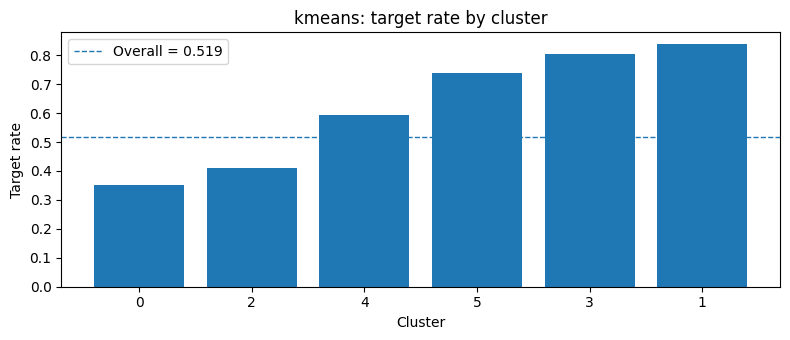

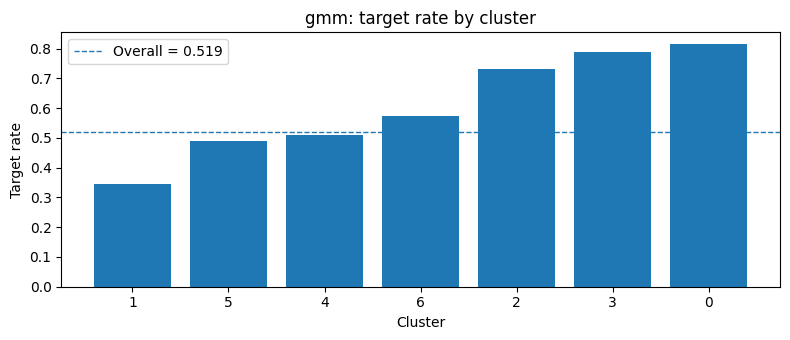

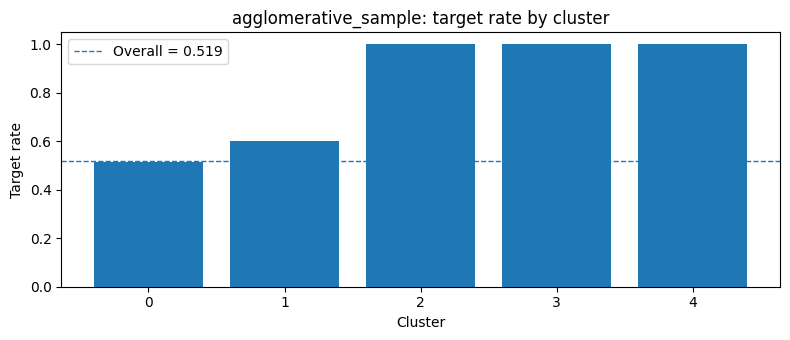

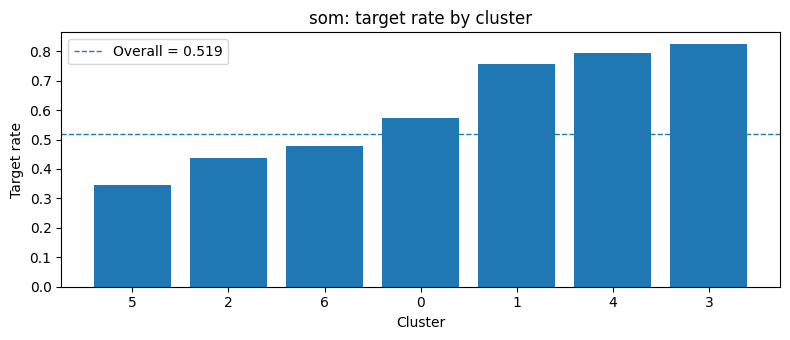

In [17]:
rate_tables = {}
for method, labels in best_by_method.items():
    if method == "agglomerative_sample":
        idx, sample_labels = labels
        rates = cluster_rate_table(sample_labels, y.iloc[idx].to_numpy(), obs_ids.iloc[idx].to_numpy())
    else:
        rates = cluster_rate_table(labels, y.to_numpy(), obs_ids.to_numpy())
    rate_tables[method] = rates
    print(f"\n{method}")
    display(rates)

# Plot cluster target rates for each selected method.
for method, rates in rate_tables.items():
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ordered = rates.sort_values("target_rate")
    ax.bar(ordered.index.astype(str), ordered["target_rate"])
    ax.axhline(y.mean(), linestyle="--", linewidth=1, label=f"Overall = {y.mean():.3f}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Target rate")
    ax.set_title(f"{method}: target rate by cluster")
    ax.legend()
    plt.tight_layout()
    plt.show()


## 11. Feature profiles and distinguishing characteristics

For each full-data solution, compare cluster means/medians with the overall population. Standardised differences are descriptive. For categorical variables, use encoded feature proportions; for readability, display the strongest features only.

In [18]:
def feature_profile(Z_frame, labels):
    frame = pd.DataFrame(Z_frame, columns=feature_names)
    frame["cluster"] = np.asarray(labels)
    return frame.groupby("cluster").mean()

profile_methods = {
    name: labels for name, labels in best_by_method.items()
    if name != "agglomerative_sample" and len(labels) == len(X)
}

for method, labels in profile_methods.items():
    prof = feature_profile(X, labels)
    overall = pd.Series(X.mean(axis=0), index=feature_names)
    sd = pd.Series(X.std(axis=0), index=feature_names).replace(0, np.nan)
    differences = (prof - overall) / sd
    print(f"\n{method}: strongest cluster-feature differences")
    for cluster_id in differences.index:
        top = differences.loc[cluster_id].abs().sort_values(ascending=False).head(MAX_FEATURES_FOR_PLOTS).index
        display(differences.loc[[cluster_id], top].T.rename(columns={cluster_id: f"cluster_{cluster_id}"}))


kmeans: strongest cluster-feature differences


cluster,cluster_0
numeric__n_spend_groups_used,0.794919
numeric__run_n_purchases,0.754540
numeric__crccreditlimit_slog,0.719352
numeric__m0_total_due_with_arrears_slog,0.685616
numeric__run_nonessential_slog,0.664850
numeric__run_grp_debt_repayment_slog,0.629010
numeric__run_income_slog,0.615745
numeric__run_in_income_employment_slog,0.602620
numeric__income_type_p0_rank,0.580109
numeric__product_group_NPDM,0.565883


cluster,cluster_1
numeric__no_complete_cycle,2.067717
numeric__income_cv,1.637705
numeric__days_since_last_income,1.217133
numeric__income_type_p0_rank,-0.982152
numeric__recent_vs_avg_income,-0.948383
numeric__n_spend_groups_used,-0.891077
numeric__run_nonessential_slog,-0.823404
numeric__run_n_bounced,0.717966
numeric__run_n_purchases,-0.663426
numeric__run_in_income_informal_slog,-0.611903


cluster,cluster_2
numeric__m0_arrearsamount_slog,-0.802586
numeric__m0_total_due_with_arrears_slog,-0.683609
numeric__crccreditlimit_slog,-0.584198
numeric__m0_start_cd_group_CD 1,0.449741
numeric__arrears_share_of_due,-0.428018
numeric__m0_start_cd_group_CD 3,-0.416772
numeric__no_complete_cycle,-0.393416
numeric__run_n_fees,-0.390261
numeric__cash_share_of_spend,0.345745
numeric__run_n_bounced,-0.292521


cluster,cluster_3
numeric__no_income_seen,3.880035
numeric__no_income_detected,3.558473
numeric__run_income_slog,-3.282324
numeric__days_since_last_income,2.639675
numeric__no_complete_cycle,2.141459
numeric__n_spend_groups_used,-1.883140
numeric__run_nonessential_slog,-1.703507
numeric__run_grp_debt_repayment_slog,-1.375175
numeric__income_type_p0_rank,-1.072563
numeric__run_in_income_informal_slog,-1.068726


cluster,cluster_4
numeric__unemployed_now,3.969668
numeric__run_income_slog,-0.536135
numeric__run_in_income_employment_slog,-0.503570
numeric__m0_total_due_with_arrears_slog,-0.392494
numeric__cash_share_of_spend,0.379583
numeric__income_type_p0_rank,-0.325920
numeric__m0_arrearsamount_slog,-0.323309
numeric__days_since_last_income,0.302643
numeric__run_grp_debt_repayment_slog,0.289904
numeric__product_group_NPDM,-0.257181


... (13 outputs left out)

cluster,cluster_3
numeric__no_complete_cycle,1.933399
numeric__income_cv,1.551200
numeric__days_since_last_income,1.172007
numeric__income_type_p0_rank,-0.952503
numeric__recent_vs_avg_income,-0.919207
numeric__n_spend_groups_used,-0.895900
numeric__run_nonessential_slog,-0.815345
numeric__run_n_purchases,-0.657009
numeric__run_in_income_informal_slog,-0.645792
numeric__run_n_bounced,0.559256


cluster,cluster_4
numeric__no_income_seen,3.816717
numeric__run_income_slog,-3.259608
numeric__no_income_detected,3.069253
numeric__days_since_last_income,2.636992
numeric__no_complete_cycle,1.942331
numeric__n_spend_groups_used,-1.771880
numeric__run_nonessential_slog,-1.607971
numeric__run_grp_debt_repayment_slog,-1.192712
numeric__income_type_p0_rank,-1.033066
numeric__run_in_income_informal_slog,-0.944871


cluster,cluster_5
numeric__run_in_income_employment_slog,0.833124
numeric__run_grp_debt_repayment_slog,0.757291
numeric__income_type_p0_rank,0.663073
numeric__n_spend_groups_used,0.594817
numeric__run_income_slog,0.547466
numeric__grp_debt_repayment_share,0.507822
numeric__run_n_purchases,0.485866
numeric__run_nonessential_slog,0.480156
numeric__committed_share_of_spend,0.472290
numeric__m0_start_cd_group_CD 1,0.435375


cluster,cluster_6
numeric__pay_frequency_weekly,3.190228
numeric__income_type_p0_rank,0.771171
numeric__n_spend_groups_used,0.603779
numeric__run_nonessential_slog,0.558894
numeric__run_n_purchases,0.553069
numeric__run_income_slog,0.472032
numeric__days_since_last_income,-0.438135
numeric__no_complete_cycle,-0.415084
numeric__run_in_income_informal_slog,0.360987
numeric__cash_share_of_spend,-0.267627


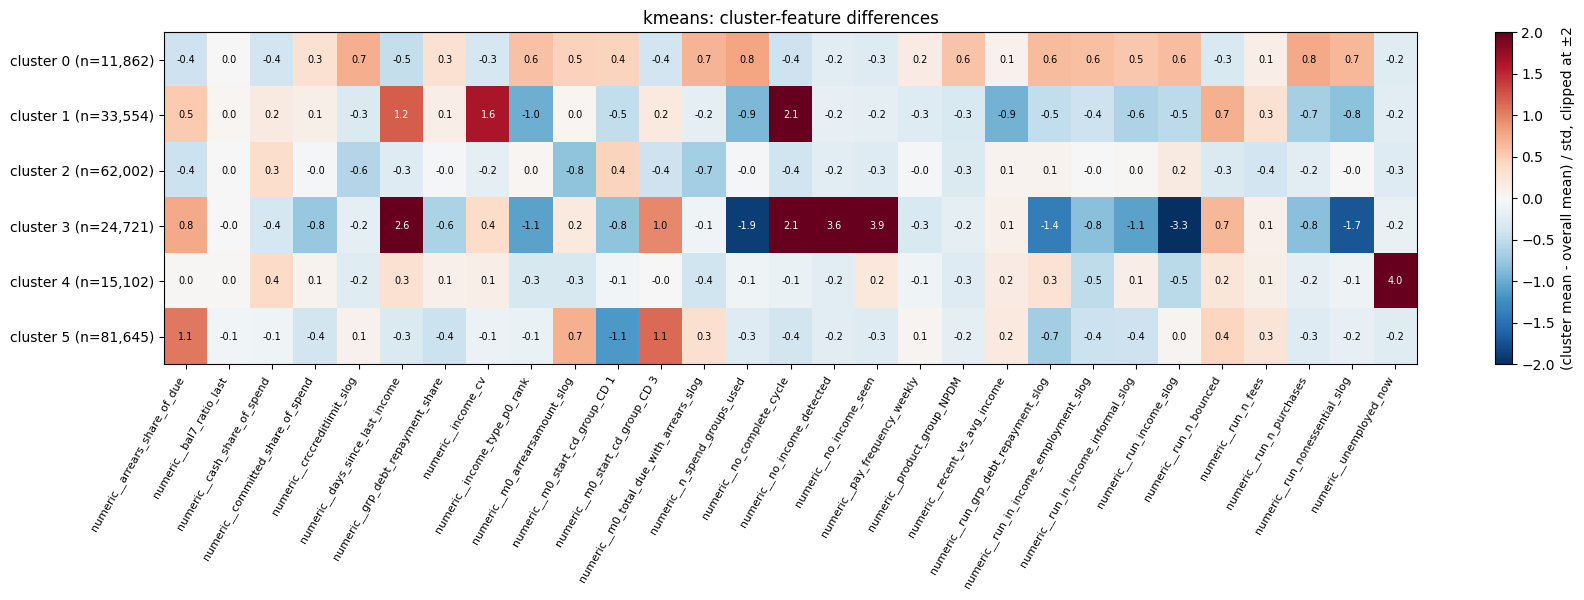

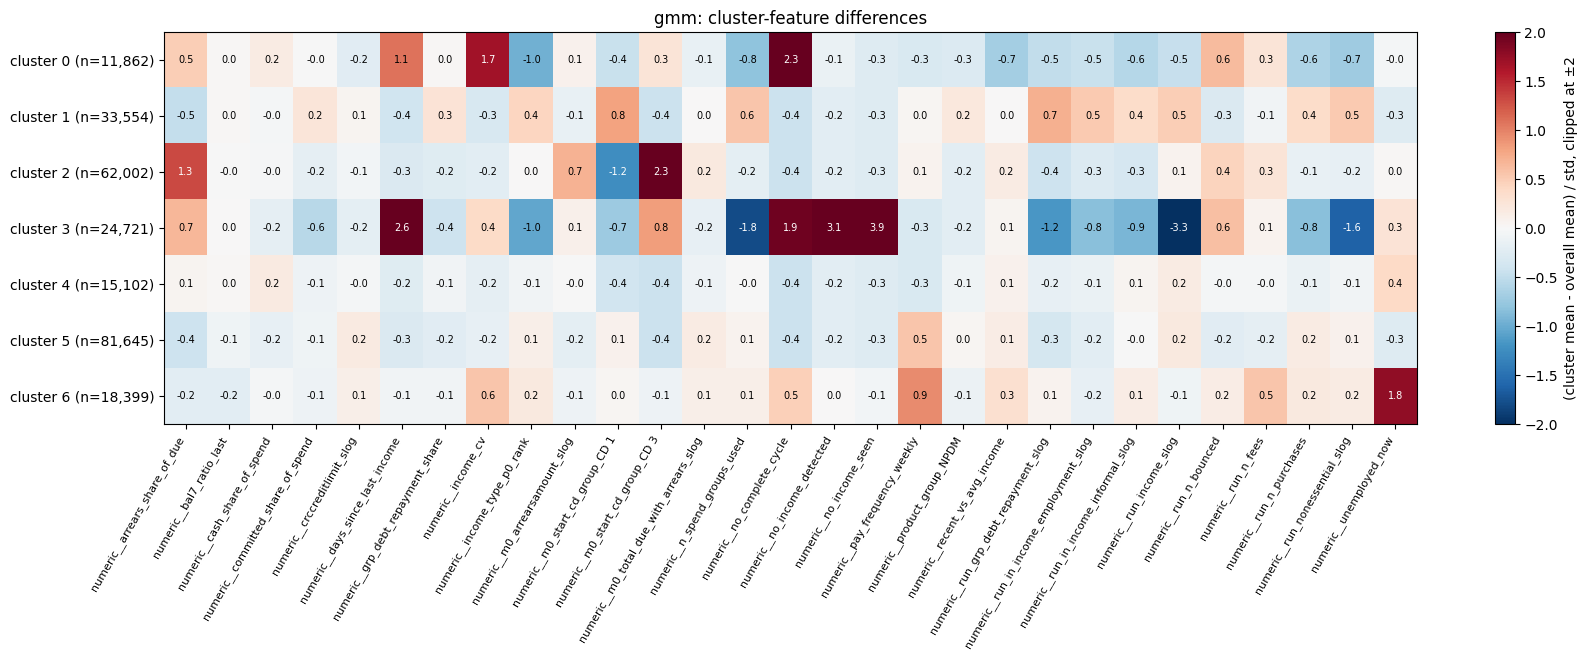

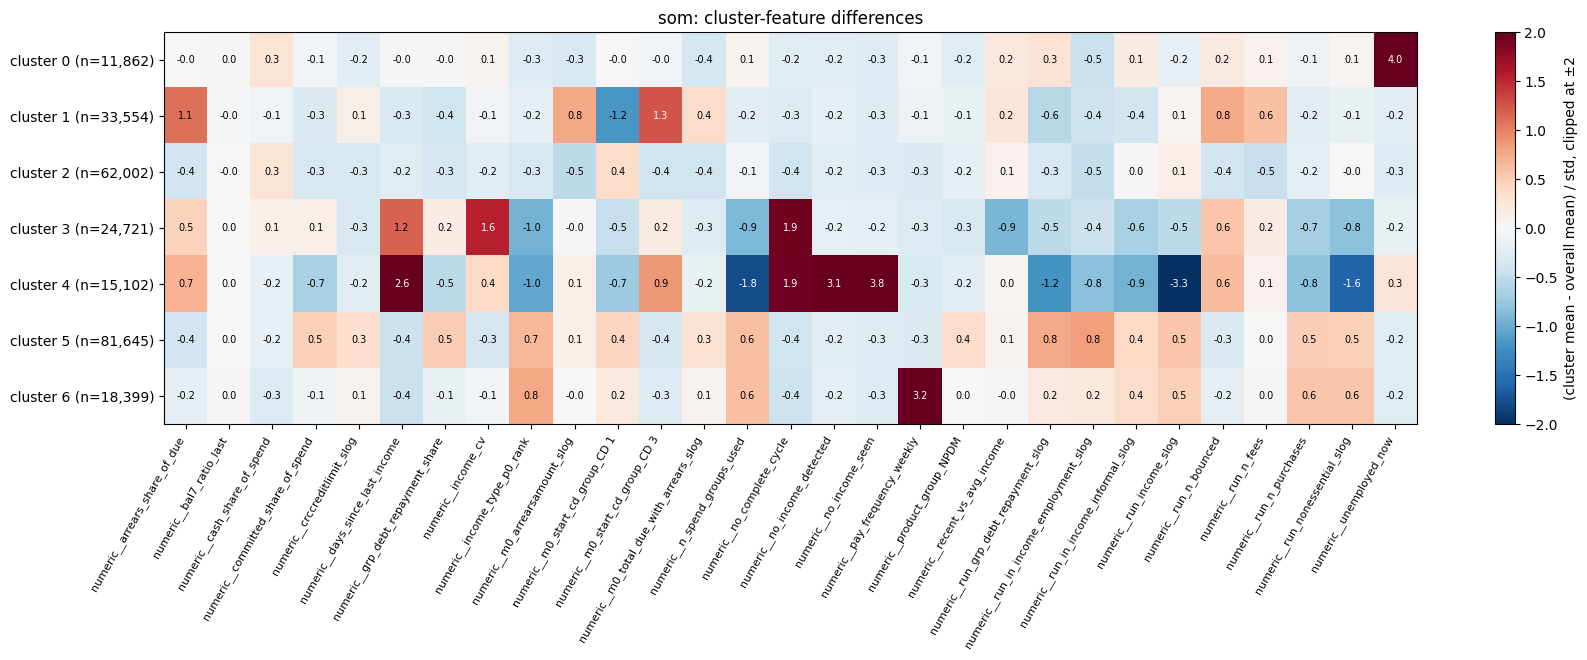

In [26]:
import re
CLIP = 2.0            # colour scale limit, in standard deviations
TOP_PER_CLUSTER = 8   # features picked per cluster, so every cluster gets columns

for method, labels in profile_methods.items():
    prof = feature_profile(X, np.asarray(labels))
    overall = pd.Series(X.mean(axis=0), index=feature_names)
    sd = pd.Series(X.std(axis=0), index=feature_names).replace(0, np.nan)

    differences = (prof - overall) / sd

    # Include every feature
    M = differences
    all_features = M.columns.tolist()

    fig, ax = plt.subplots(
        figsize=(max(7, 0.5 * len(all_features) + 3), 0.6 * len(M) + 2.5)
    )

    im = ax.imshow(
        M.clip(-CLIP, CLIP).to_numpy(),
        cmap="RdBu_r",
        vmin=-CLIP,
        vmax=CLIP,
        aspect="auto"
    )

    ax.set_xticks(range(len(all_features)))
    ax.set_xticklabels(all_features, rotation=60, ha="right", fontsize=8)

    ax.set_yticks(range(len(M)))
    ax.set_yticklabels([f"cluster {c} (n={sizes[c]:,})" for c in M.index])

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            if abs(v) >= 0.0:
                ax.text(
                    j, i, f"{v:.1f}",
                    ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 1.2 else "black"
                )

    fig.colorbar(
        im, ax=ax,
        label=f"(cluster mean - overall mean) / std, clipped at ±{CLIP:g}"
    )

    ax.set_title(f"{method}: cluster-feature differences")
    fig.tight_layout()
    plt.show()

In [27]:
# Saving those differences
all_rows = []
for method, labels in profile_methods.items():
    labels = np.asarray(labels)
    prof = feature_profile(X, labels)
    overall = pd.Series(X.mean(axis=0), index=feature_names)
    sd = pd.Series(X.std(axis=0), index=feature_names).replace(0, np.nan)
    differences = (prof - overall) / sd

    long = pd.concat(
        [differences.rename_axis(index="cluster", columns="feature").stack().rename("standardised_difference"),
         prof.rename_axis(index="cluster", columns="feature").stack().rename("cluster_mean")],
        axis=1).reset_index()
    long.insert(0, "method", method)
    long["overall_mean"] = long["feature"].map(overall)
    sizes = pd.Series(labels).value_counts()
    long["cluster_size"] = long["cluster"].map(sizes)
    long["cluster_share"] = long["cluster_size"] / len(labels)
    long["abs_difference"] = long["standardised_difference"].abs()
    long["rank_in_cluster"] = (long.groupby("cluster")["abs_difference"]
                                   .rank(ascending=False, method="first").astype(int))
    all_rows.append(long)

diff_table = (pd.concat(all_rows, ignore_index=True)
                .sort_values(["method", "cluster", "rank_in_cluster"]).reset_index(drop=True))

# 1. Everything, long format: one row per method x cluster x feature
diff_table.to_csv(OUT_DIR / "cluster_feature_differences_all_methods.csv", index=False)

# 2. Only the strongest features per cluster (same cut as your plots)
diff_table[diff_table["rank_in_cluster"] <= MAX_FEATURES_FOR_PLOTS].to_csv(
    OUT_DIR / "cluster_feature_differences_top.csv", index=False)

# 3. One wide file per method: features as rows, clusters as columns
for method, g in diff_table.groupby("method"):
    (g.pivot(index="feature", columns="cluster", values="standardised_difference")
       .add_prefix("cluster_")
       .to_csv(OUT_DIR / f"cluster_feature_differences_{method}.csv"))

## 12. Optional target-rate significance check

A chi-square test assesses whether target incidence is independent of cluster assignment. This is a descriptive association test, not a causal test. With very large samples, small differences can become statistically significant, so inspect effect sizes and confidence intervals too.

In [28]:
from scipy.stats import chi2_contingency

association_rows = []
for method, labels in profile_methods.items():
    contingency = pd.crosstab(pd.Series(labels, name="cluster"), y.reset_index(drop=True))
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    n_total = contingency.to_numpy().sum()
    # Cramer's V effect size
    denom = n_total * min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / denom) if denom > 0 else np.nan
    association_rows.append({
        "method": method, "chi2": chi2, "degrees_freedom": dof,
        "p_value": p_value, "cramers_v": cramers_v,
    })

association_results = pd.DataFrame(association_rows)
display(association_results)


,method,chi2,degrees_freedom,p_value,cramers_v
0,kmeans,34327.642843,5,0.0,0.372583
1,gmm,28203.529307,6,0.0,0.337717
2,som,33292.736588,6,0.0,0.366924


## 13. Export assignments, profiles, and tuning results

The exported assignment file maps each `obs_id` to its cluster. It is suitable for joining back to the client-level dataframe. Agglomerative labels are exported separately if tuning used a sample.

In [29]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

all_results.to_csv(OUT_DIR / "clustering_tuning_results.csv", index=False)
association_results.to_csv(OUT_DIR / "target_cluster_association.csv", index=False)

for method, labels in profile_methods.items():
    assignments = pd.DataFrame({
        OBS_ID: obs_ids.to_numpy(),
        "cluster": np.asarray(labels),
        TARGET: y.to_numpy(),
    })
    assignments.to_csv(OUT_DIR / f"{method}_assignments.csv", index=False)
    cluster_rate_table(labels, y.to_numpy(), obs_ids.to_numpy()).to_csv(
        OUT_DIR / f"{method}_target_rates.csv"
    )

if "agglomerative_sample" in best_by_method:
    idx, labels = best_by_method["agglomerative_sample"]
    pd.DataFrame({
        OBS_ID: obs_ids.iloc[idx].to_numpy(),
        "cluster": labels,
        TARGET: y.iloc[idx].to_numpy(),
    }).to_csv(OUT_DIR / "agglomerative_sample_assignments.csv", index=False)

print("Saved outputs to:", OUT_DIR.resolve())


Saved outputs to: /Users/hoyle/Documents/Uni/4th_Year/Methods/MOR-assignment3/client_cluster_analysis_full_dataset


## 14. Target Rule Analysis

In [30]:
lab = D["labels"]
target_rule = lab["target_rule"]
y_arr = np.asarray(target_rule)

In [31]:
# add the Gini columns to each results table
if kmeans_results is not None and not kmeans_results.empty:
    g = [gini_scores(kmeans_models[int(r.k)][1], y_arr) for r in kmeans_results.itertuples()]
    kmeans_results = pd.concat([kmeans_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

if gmm_results is not None and not gmm_results.empty:
    g = [gini_scores(gmm_models[(int(r.components), r.covariance_type)][0].predict(X), y_arr)
         for r in gmm_results.itertuples()]
    gmm_results = pd.concat([gmm_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)
"""
if agg_results is not None and not agg_results.empty:      # tuned on a sample: score against the sample's target
    g = [gini_scores(agg_models[(int(r.k), r.linkage)][1], y_arr[agg_idx]) for r in agg_results.itertuples()]
    agg_results = pd.concat([agg_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)
"""

if som_results is not None and not som_results.empty:      # slowest part: one pass over X per SOM candidate
    keys = [(int(r.rows), int(r.cols), float(r.sigma), float(r.learning_rate), int(r.epochs), int(r.cluster_k))
            for r in som_results.itertuples()]
    g = [gini_scores(som_labels_for(k), y_arr) for k in keys]
    som_results = pd.concat([som_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

KeyboardInterrupt: 

In [ ]:
candidate_tables = []
for name, table in [("kmeans", kmeans_results), ("gmm", gmm_results), ("som", som_results)]:
    if table is not None and not table.empty:
        table = table.loc[:, ~table.columns.duplicated(keep="last")].reset_index(drop=True)
        if "method" in table.columns:
            table = table.rename(columns={"method": "method_detail"})   # keep the original column, under another name
        table.insert(0, "method", name)
        candidate_tables.append(table)

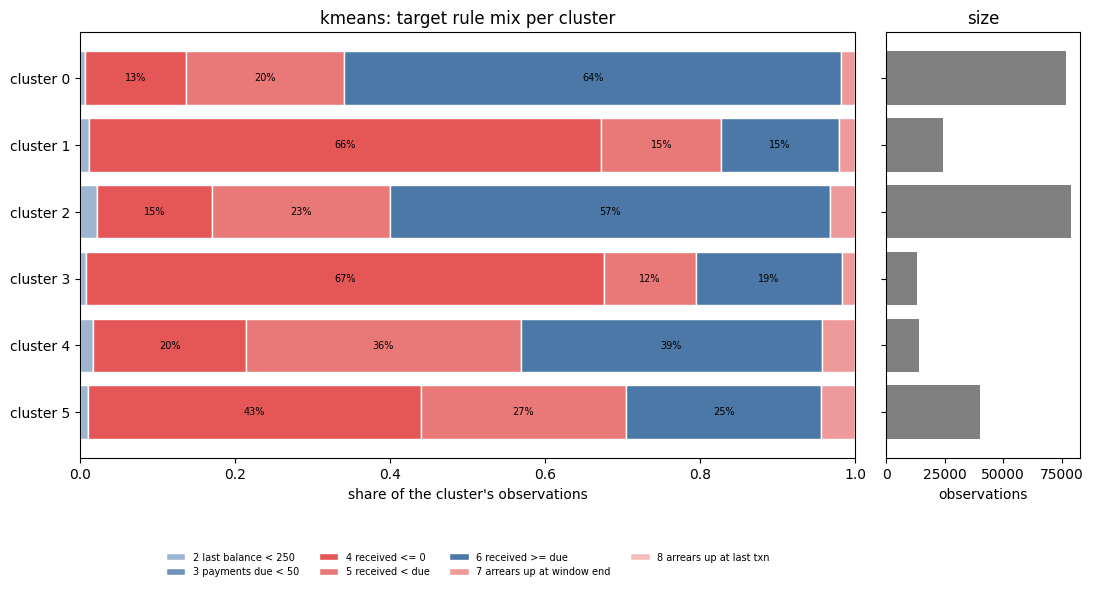

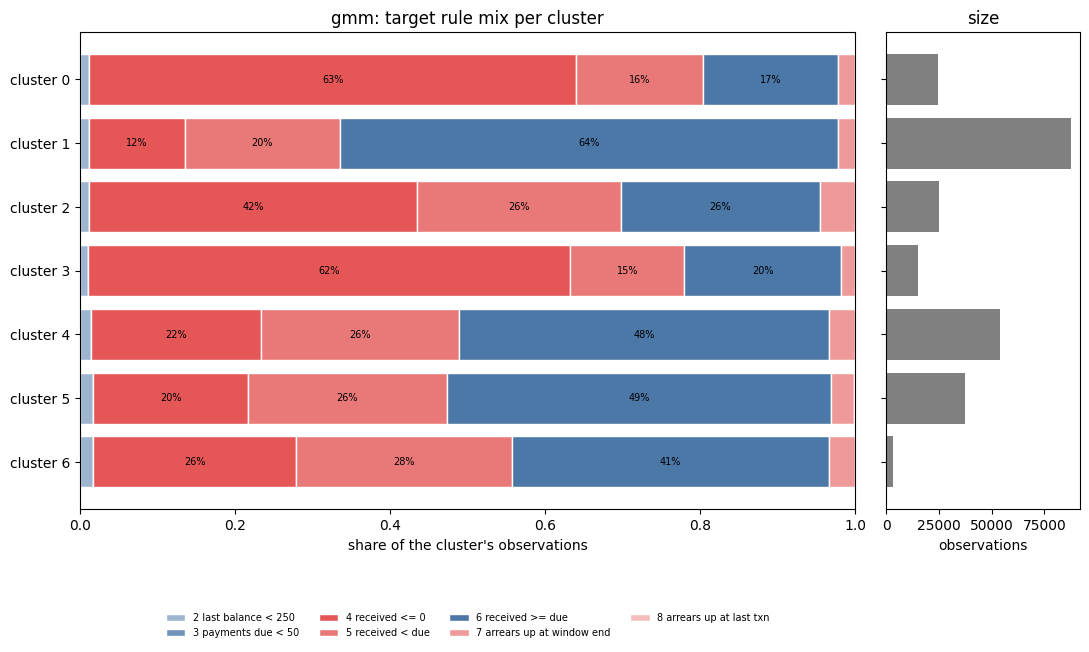

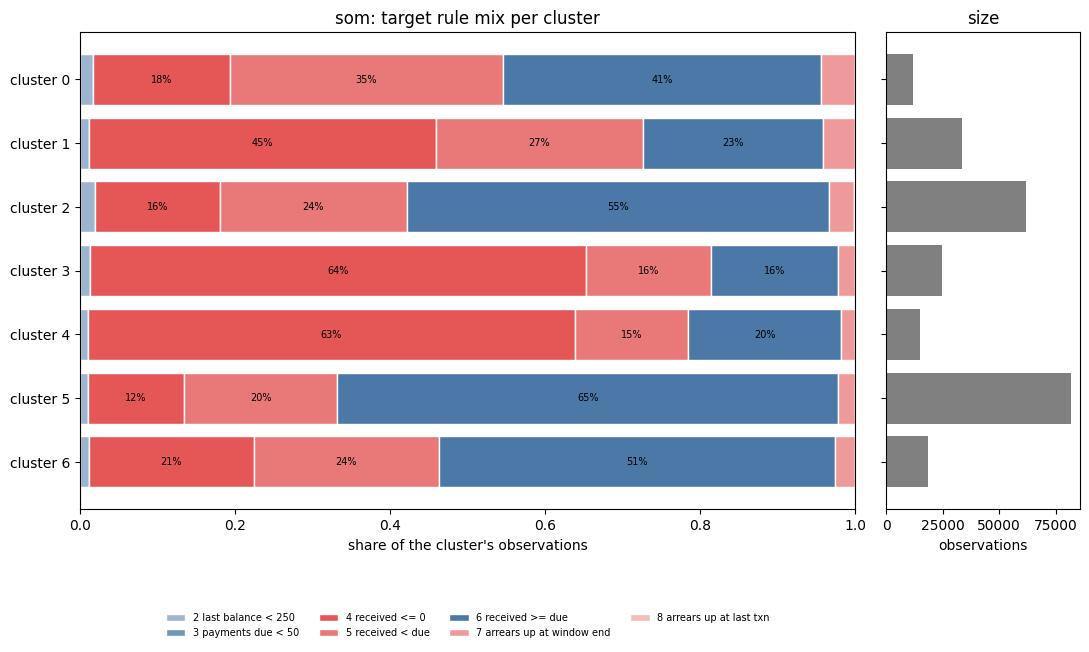

In [32]:
import matplotlib.colors as mc

# rule for every row of X, same order as X (numbers 2-8). Use your own variable here.
# e.g. rule_arr = lab["target_rule"].to_numpy()   or   rule.loc[X.index].to_numpy()
rule_arr = y_arr

RULE_TO_TARGET = {2: 0, 3: 0, 4: 1, 5: 1, 6: 0, 7: 1, 8: 1}
RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0", 5: "5 received < due",
              6: "6 received >= due", 7: "7 arrears up at window end", 8: "8 arrears up at last txn"}
rules = sorted(RULE_TO_TARGET)

# blues = target 0, reds = target 1 (so the bar also shows the binary mix at a glance)
shade = {2: .55, 3: .8, 6: 1.0, 4: 1.0, 5: .8, 7: .6, 8: .4}
def tint(c, a): return tuple(a * np.array(mc.to_rgb(c)) + (1 - a) * np.ones(3))
colors = {r: tint("#4c78a8" if RULE_TO_TARGET[r] == 0 else "#e45756", shade[r]) for r in rules}

rule_mix = {}
for method, labels in profile_methods.items():
    df = pd.DataFrame({"cluster": np.asarray(labels), "rule": rule_arr}).dropna()
    df["rule"] = df["rule"].astype(int)
    ct = pd.crosstab(df["cluster"], df["rule"]).reindex(columns=rules, fill_value=0)
    share = ct.div(ct.sum(axis=1), axis=0)
    size = ct.sum(axis=1)
    rule_mix[method] = share

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 0.6 * len(ct) + 2.5), sharey=True,
                                  gridspec_kw={"width_ratios": [4, 1]})
    left = np.zeros(len(ct))
    for r in rules:
        ax.barh(range(len(ct)), share[r], left=left, color=colors[r], edgecolor="white", label=RULE_NAMES[r])
        for i, v in enumerate(share[r]):
            if v >= 0.06:
                ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=7)
        left += share[r].to_numpy()
    ax.set_yticks(range(len(ct))); ax.set_yticklabels([f"cluster {c}" for c in ct.index]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xlabel("share of the cluster's observations")
    ax.set_title(f"{method}: target rule mix per cluster")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=7, frameon=False)
    ax2.barh(range(len(ct)), size, color="grey"); ax2.set_xlabel("observations"); ax2.set_title("size")
    fig.tight_layout()
    plt.show()